# 06 · Reliability analysis

Firmware-attributable failures (reboots) are kept separate from real hardware degradation (bearing faults from IMS),
so bearing wear is not blamed on the firmware and firmware bugs are not explained away as wear.

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
P = ROOT / "data" / "processed"

In [2]:
from src.reliability_analysis import mtbf_table, time_to_first_reboot, kaplan_meier, logrank_test, bearing_health, degradation_summary
from src.preprocessing import load_ims_features
tel = pd.read_parquet(P / "telemetry.parquet")
mtbf_table(tel)

,firmware_version,hw_revision,devices,operating_hours,reboots,hw_fault_intervals,availability_pct,mtbf_reboot_hours,mtbf_ci_low,mtbf_ci_high
0,1.0.0,A,109,3023.9738,17,170,99.4728,177.8808,111.0993,305.3555
1,1.0.0,B,43,1198.8695,10,0,99.9058,119.8870,65.1901,250.0047
2,2.0.0,A,66,1312.0855,8,84,99.4004,164.0107,83.2373,379.8927
3,2.0.0,B,26,516.2175,24,17,99.2726,21.5091,14.4558,33.5702


rev A: log-rank {'chi2': 0.09431777873641456, 'p_value': 0.7587581263607605}
rev B: log-rank {'chi2': 11.747109147977133, 'p_value': 0.0006093781342696988}


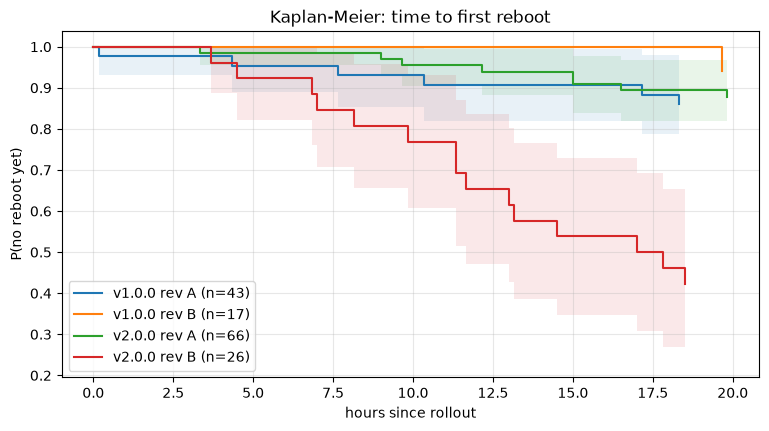

In [3]:
ttf = time_to_first_reboot(tel)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (fw, rev), g in ttf.groupby(["firmware_version", "hw_revision"]):
    km = kaplan_meier(g.duration_h, g.event)
    ax.step(km.time, km.survival, where="post", label=f"v{fw} rev {rev} (n={len(g)})")
    ax.fill_between(km.time, km.ci_low, km.ci_high, step="post", alpha=0.1)
ax.set(xlabel="hours since rollout", ylabel="P(no reboot yet)", title="Kaplan-Meier: time to first reboot"); ax.legend()
for rev, g in ttf.groupby("hw_revision"):
    a, b = g[g.group == "control"], g[g.group == "treatment"]
    print(f"rev {rev}: log-rank", logrank_test(a.duration_h, a.event, b.duration_h, b.event))

### Hardware degradation is independent of firmware
Hardware faults come from the real bearing signal. If firmware were blamed for them, rev-A devices that happen to be
near end of life would look like regressions.

In [4]:
tel.groupby(["group", "period"]).agg(hw_fault_rate_pct=("hardware_fault", lambda s: 100 * s.mean()),
                                     reboot_rate_pct=("reboot", lambda s: 100 * s.mean()))

hw_fault_rate_pct  reboot_rate_pct
group     period                                    
control   post               0.8611           0.0972
          pre                0.0000           0.0972
treatment post               0.9149           0.2899
          pre                0.9783           0.1178

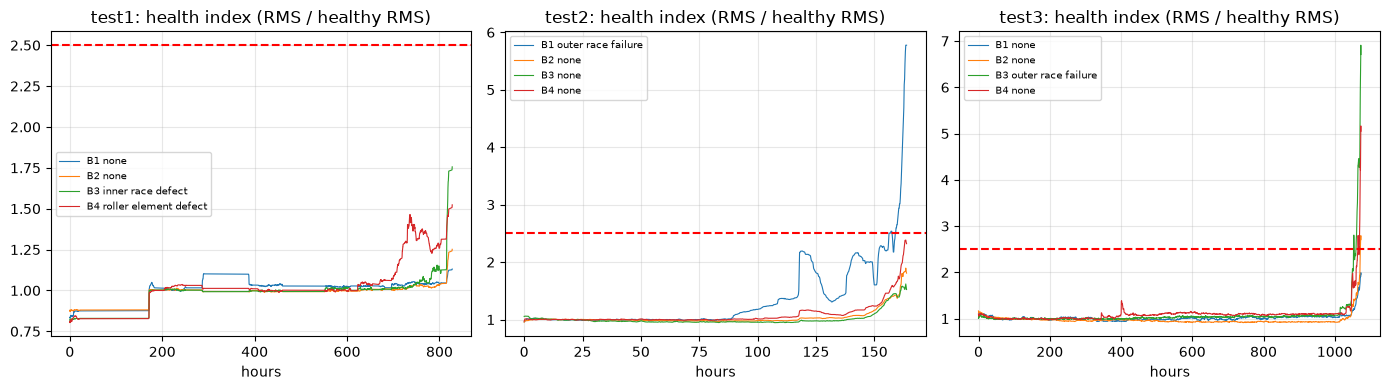

In [5]:
health = bearing_health(load_ims_features())
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (test, g) in zip(axes, health.groupby("test_id")):
    for b, gb in g.groupby("bearing"):
        ax.plot(gb.hours, gb.health_index_smooth, lw=0.8, label=f"B{b} {gb.failure_mode.iloc[0]}")
    ax.axhline(2.5, color="red", ls="--"); ax.set_title(f"{test}: health index (RMS / healthy RMS)"); ax.set_xlabel("hours"); ax.legend(fontsize=7)
plt.tight_layout()

In [6]:
degradation_summary(health)

,test_id,bearing,failure_mode,run_hours,hours_to_rms_threshold,hours_to_kurtosis_threshold,final_health_index,max_kurtosis,warning_lead_hours
0,test1,1,none,827.5589,NaN,NaN,1.1309,4.6995,NaN
1,test1,2,none,827.5589,NaN,NaN,1.2517,3.7242,NaN
2,test1,3,inner race defect,827.5589,NaN,748.0089,1.7561,74.5618,79.5500
3,test1,4,roller element defect,827.5589,NaN,673.8286,1.5237,74.5543,153.7303
4,test2,1,outer race failure,163.8333,156.3333,163.3333,5.7756,17.1100,7.5000
5,test2,2,none,163.8333,NaN,NaN,1.8082,5.4527,NaN
6,test2,3,none,163.8333,NaN,0.0000,1.5232,6.7012,163.8333
7,test2,4,none,163.8333,NaN,NaN,2.3214,4.6527,NaN
8,test3,1,none,1073.2525,NaN,NaN,1.9581,5.0641,NaN
9,test3,2,none,1073.2525,1071.5858,NaN,2.7086,3.9367,1.6667


**Takeaways**
* v2.0 on rev B cuts reboot MTBF several-fold, and the log-rank test confirms earlier reboots. This is a firmware reliability regression.
* v2.0 on rev A shows no reboot or availability change.
* Real bearing faults appear at the same rate in both arms, as randomisation intends.
* On IMS, kurtosis gives earlier warning than RMS for test 1's inner-race and roller defects. RMS gives earlier
  warning for outer-race failures. Healthy bearing 3 in test 2 runs with high kurtosis throughout, a known false-positive
  case for a fixed kurtosis threshold.